# ![Boids Logo](Logo/boid.png) 


# Serial Boid Tests and Benchmarks

**Concurrent Development - Software Development - Year 4, Semester 1 - 2026**  

**South East Technological University**

*23/11/2026*

*Author: Mark Lambert*

This notebook measures the serial update benchmark for 100, 500 and 1000 boids

The benchmark restores the same starting boid state for each iteration and excludes setup and drawing from the timed section

Run the notebook from the repository checkout with Go and the project dependencies installed

---
*Team A.D.A.M - Adam Noonan, Dorian Nowacki, Amelia Hamulewicz, Mark Lambert*

In [1]:
from pathlib import Path
import platform
import re
import shutil
import statistics
import subprocess
import pandas as pd

# walk up from where jupyter is running, looking for the boids project
project_folder = None
current = Path.cwd()
while True:
    if (current / 'boids' / 'go.mod').exists():
        project_folder = current
        break
    if current == current.parent:   # reached the top of the drive, stop
        break
    current = current.parent
boids_folder = project_folder / 'boids'

# find the Go executable
go_exe = shutil.which('go')

# show current system for testing
print(f'Platform: {platform.platform()}')
print(subprocess.run([go_exe, 'version'], cwd=boids_folder, check=True, text=True, capture_output=True).stdout.strip())
print(subprocess.run([go_exe, 'env', 'GOOS', 'GOARCH'], cwd=boids_folder, check=True, text=True, capture_output=True).stdout.strip())

Platform: macOS-15.8.3-x86_64-i386-64bit-Mach-O
go version go1.27.1 darwin/amd64
darwin
amd64


## Serial Benchmark

Each benchmark size is run five times using the `-count=5` flag, `subprocess.run` is used to spawn a new process that runs the benchmark passing in `go test ./tests -run '^$' -bench '^BenchmarkSerial$' -count=5` as the full argument

In [2]:
result = subprocess.run(
    [go_exe, 'test', './tests', '-run', '^$', '-bench', '^BenchmarkSerial$', '-benchtime=100x', '-count=5'],
    cwd=boids_folder, text=True, capture_output=True, check=True
)
print(result.stdout)

# pull the timings from each line eg, BenchmarkSerial/100-12   4095   288528 ns/op
timings = {}
for line in result.stdout.splitlines():
    match = re.match(r'^BenchmarkSerial/(\d+)-\d+\s+\d+\s+([\d.]+)\s+ns/op', line)
    if match:
        boid_count = int(match.group(1))
        nanoseconds = float(match.group(2))
        if boid_count in timings:
            timings[boid_count].append(nanoseconds)
        else:
            timings[boid_count] = [nanoseconds]

boids = sorted(timings)
df = pd.DataFrame({'Boids': boids})

df['Median ns/op'] = [statistics.median(timings[n]) for n in boids]

df

goos: darwin
goarch: amd64
pkg: boids/tests
cpu: Intel(R) Core(TM) i7-8569U CPU @ 2.80GHz
BenchmarkSerial/25-8         	     100	     18418 ns/op
BenchmarkSerial/25-8         	     100	     11832 ns/op
BenchmarkSerial/25-8         	     100	     12257 ns/op
BenchmarkSerial/25-8         	     100	     12856 ns/op
BenchmarkSerial/25-8         	     100	     11866 ns/op
BenchmarkSerial/50-8         	     100	     70414 ns/op
BenchmarkSerial/50-8         	     100	     58417 ns/op
BenchmarkSerial/50-8         	     100	     74483 ns/op
BenchmarkSerial/50-8         	     100	     74259 ns/op
BenchmarkSerial/50-8         	     100	     66015 ns/op
BenchmarkSerial/100-8        	     100	    219541 ns/op
BenchmarkSerial/100-8        	     100	    208959 ns/op
BenchmarkSerial/100-8        	     100	    207789 ns/op
BenchmarkSerial/100-8        	     100	    204542 ns/op
BenchmarkSerial/100-8        	     100	    206559 ns/op
BenchmarkSerial/500-8        	     100	   5068479 ns/op
BenchmarkSeria

,Boids,Median ns/op
0,25,12257.0
1,50,70414.0
2,100,207789.0
3,500,5158066.0
4,1000,21225115.0


Doubling the boids from 500 to 1000 roughly quadruples the time, and 100 to 1000 is ~x96, close to the x100 you'd expect if every boid checks every other boid. That confirms the serial implementation is **O(n2)**

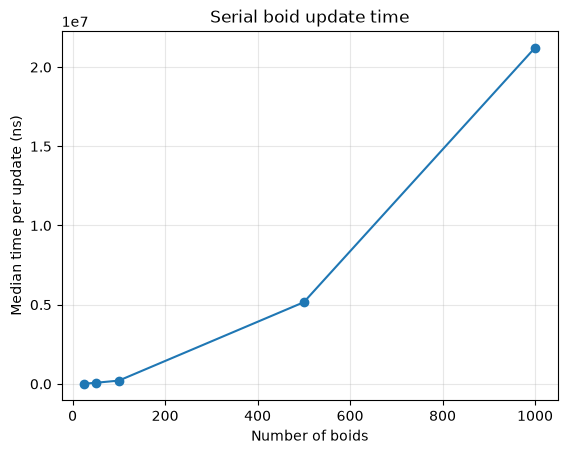

In [3]:
import matplotlib.pyplot as plt

boid_counts = sorted(timings)
median_ms = []
for boid_count in boid_counts:
    median = statistics.median(timings[boid_count])
    median_ms.append(median)

plt.plot(boid_counts, median_ms, marker='o')
plt.xlabel('Number of boids')
plt.ylabel('Median time per update (ns)')
plt.title('Serial boid update time')
plt.grid(alpha=0.3)
plt.show()

## Parallel Benchmark

Each boid and worker count combination runs five times, with 100 flock updates per run.<br>
`go test ./tests -run '^$' -bench '^BenchmarkParallel$' -benchtime=100x -count=5`

In [4]:
parallel_result = subprocess.run(
    [go_exe, 'test', './tests', '-run', '^$', '-bench', '^BenchmarkParallel$', '-benchtime=100x', '-count=5'],
    cwd=boids_folder, text=True, capture_output=True, check=True
)
print(parallel_result.stdout)

# Pull timings from lines like: BenchmarkParallel/100/4_workers-8   100   103234 ns/op
parallel_timings = {}
for line in parallel_result.stdout.splitlines():
    match = re.match(r'^BenchmarkParallel/(\d+)/(\d+)_workers-\d+\s+\d+\s+([\d.]+)\s+ns/op', line)
    if match:
        boid_count = int(match.group(1))
        worker_count = int(match.group(2))
        nanoseconds = float(match.group(3))
        key = (boid_count, worker_count)

        if key in parallel_timings:
            parallel_timings[key].append(nanoseconds)
        else:
            parallel_timings[key] = [nanoseconds]

boids = [25, 50, 100, 500, 1000]
df = pd.DataFrame({'Boids': boids})

df['1 worker'] = [statistics.median(parallel_timings[n, 1]) for n in boids]
df['2 workers'] = [statistics.median(parallel_timings[n, 2]) for n in boids]
df['4 workers'] = [statistics.median(parallel_timings[n, 4]) for n in boids]
df['8 workers'] = [statistics.median(parallel_timings[n, 8]) for n in boids]
df['10 workers'] = [statistics.median(parallel_timings[n, 10]) for n in boids]

print('Median time per flock update (ns/op)')
df

goos: darwin
goarch: amd64
pkg: boids/tests
cpu: Intel(R) Core(TM) i7-8569U CPU @ 2.80GHz
BenchmarkParallel/25/1_workers-8         	     100	     25944 ns/op
BenchmarkParallel/25/1_workers-8         	     100	     17755 ns/op
BenchmarkParallel/25/1_workers-8         	     100	     19578 ns/op
BenchmarkParallel/25/1_workers-8         	     100	     18223 ns/op
BenchmarkParallel/25/1_workers-8         	     100	     17710 ns/op
BenchmarkParallel/25/2_workers-8         	     100	     12308 ns/op
BenchmarkParallel/25/2_workers-8         	     100	     12598 ns/op
BenchmarkParallel/25/2_workers-8         	     100	     12232 ns/op
BenchmarkParallel/25/2_workers-8         	     100	     13800 ns/op
BenchmarkParallel/25/2_workers-8         	     100	     16199 ns/op
BenchmarkParallel/25/4_workers-8         	     100	     15265 ns/op
BenchmarkParallel/25/4_workers-8         	     100	     16077 ns/op
BenchmarkParallel/25/4_workers-8         	     100	     15186 ns/op
BenchmarkParallel/25/4_wor

,Boids,1 worker,2 workers,4 workers,8 workers,10 workers
0,25,18223.0,12598.0,15186.0,16486.0,15718.0
1,50,65167.0,39050.0,30897.0,34405.0,35613.0
2,100,235158.0,148274.0,109791.0,125931.0,124520.0
3,500,5824954.0,3377480.0,2947194.0,3407847.0,3186726.0
4,1000,24078982.0,14066224.0,11190008.0,15838066.0,13527348.0


## Sources
- Go (2026) testing package: Benchmarks. Available at: https://pkg.go.dev/testing#B (Accessed: 23rd Nov 2026)
- Python Software Foundation (2026) subprocess — Subprocess management. Python 3 documentation. Available at: https://docs.python.org/3/library/subprocess.html (Accessed: 23rd Nov 2026)
- GeeksforGeeks (2025) Python | shutil.which() method. Available at: https://www.geeksforgeeks.org/python/python-shutil-which-method/ (Accessed: 23 November 2026)
-Azalea (2022) ‘[How to create a table with data with a formula? (Python)](https://stackoverflow.com/questions/73924021)’, *Stack Overflow* (Accessed: 24 November 2026).